
Эксперимент 1: влияние скорости обучения (1000 эпох)
η = 0.001  MSE(train) = 0.23192988
η = 0.01   MSE(train) = 0.010287231
η = 0.05   MSE(train) = 0.0046992447
η = 0.1    MSE(train) = 0.0029225815
η = 0.5    MSE(train) = 0.51004794
η = 1.0    MSE(train) = inf


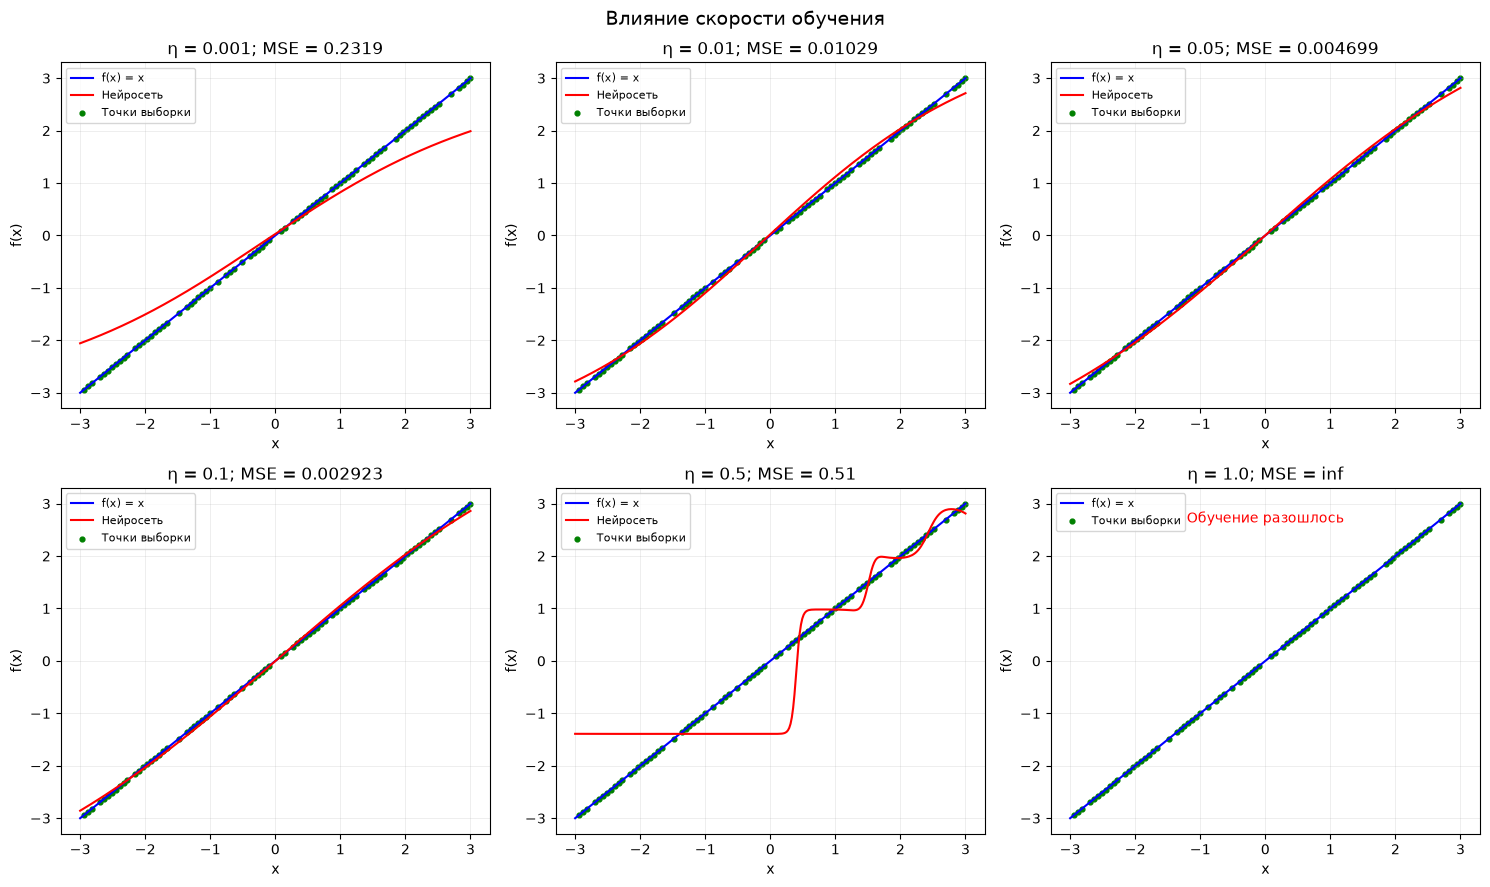

Лучшая скорость: 0.1; MSE(test) = 0.0035624723


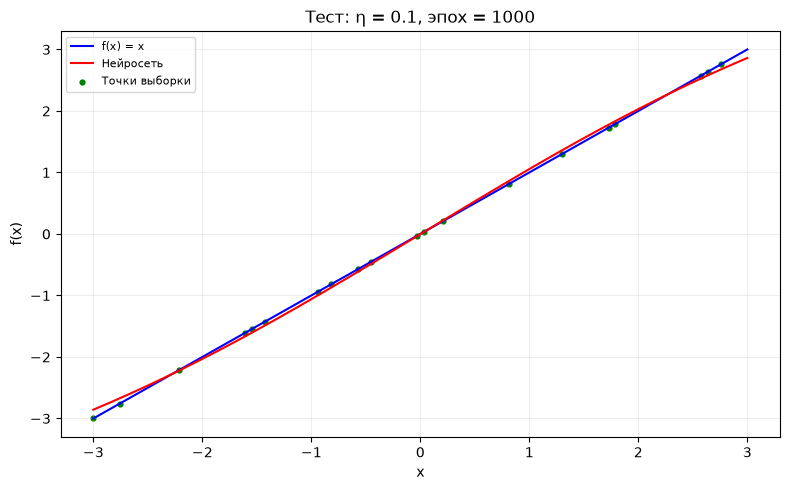


Эксперимент 2: влияние числа эпох (η = 0.01)
Эпох = 20    MSE(train) = 2.1775817
Эпох = 100   MSE(train) = 0.22959288
Эпох = 500   MSE(train) = 0.011976234
Эпох = 1000  MSE(train) = 0.010287231
Эпох = 2000  MSE(train) = 0.0079384402
Эпох = 5000  MSE(train) = 0.0046993332


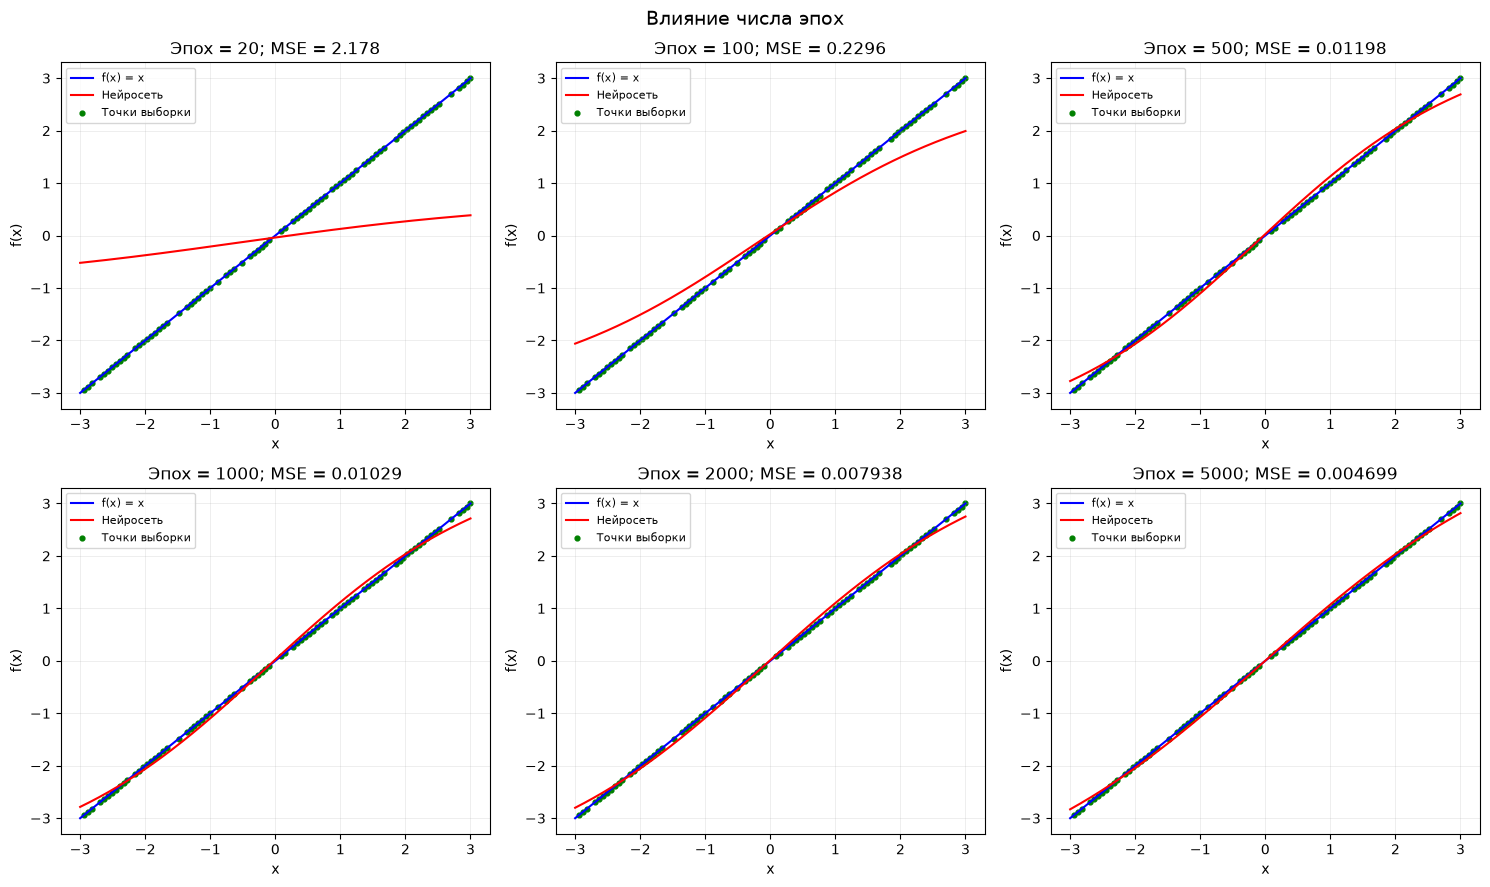

Лучшее число эпох: 5000; MSE(test) = 0.0055270278


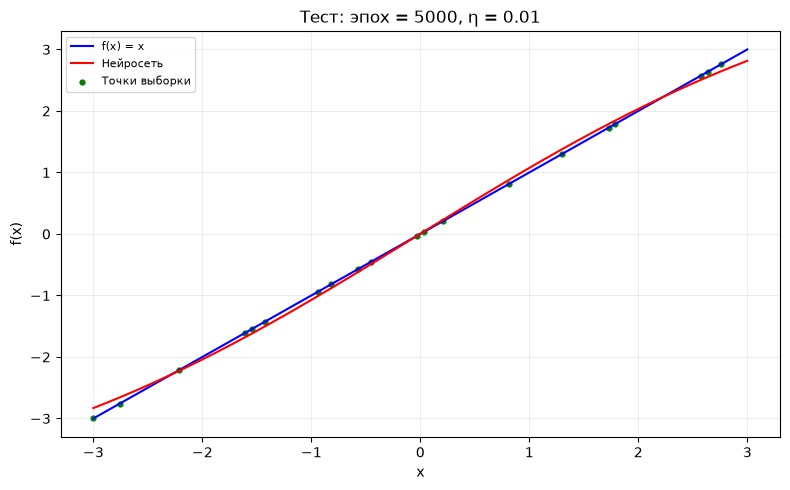

In [6]:
"""ДЗ №3, вариант 3: аппроксимация f(x) = x сетью 1–20–1.

Зависимости: numpy, matplotlib. Запуск: python variant3_clean.py.
В Jupyter можно выполнить: %run variant3_clean.py
Графики отображаются на экране и не сохраняются в файлы.
"""

import numpy as np
import matplotlib.pyplot as plt

NEURONS = 20
LEARNING_RATES = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0]
EPOCH_COUNTS = [20, 100, 500, 1000, 2000, 5000]
BASE_RATE = 0.01
BASE_EPOCHS = 1000


def target_function(x):
    return x


def generate_data():
    """100 равномерно расположенных точек, случайное разбиение 80/20."""
    x = np.linspace(-3, 3, 100)
    y = target_function(x)
    indices = np.random.default_rng(2026).permutation(len(x))
    train_ids = indices[:80]
    test_ids = indices[80:]
    return x[train_ids], y[train_ids], x[test_ids], y[test_ids]


def initialize_weights():
    """Одинаковая начальная точка для каждого эксперимента."""
    rng = np.random.default_rng(123)
    w1 = rng.uniform(-0.5, 0.5, NEURONS)
    b1 = rng.uniform(-0.5, 0.5, NEURONS)
    w2 = rng.uniform(-0.5, 0.5, NEURONS)
    b2 = 0.0

    return [w1, b1, w2, b2]


def copy_weights(weights):
    return [weights[0].copy(), weights[1].copy(),
            weights[2].copy(), float(weights[3])]


def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))


def forward(x, weights):
    """Прямой проход для массива x: скрытый слой и выход сети."""
    w1, b1, w2, b2 = weights
    hidden = np.zeros((len(x), NEURONS))
    predictions = np.full(len(x), b2, dtype=float)
    for k in range(NEURONS):
        z = w1[k] * x + b1[k]
        hidden[:, k] = sigmoid(z)
        predictions += w2[k] * hidden[:, k]
    return predictions, hidden


def backward(x, y, predictions, hidden, weights):
    """Градиенты MSE, усреднённые по всему обучающему набору."""
    n = len(x)
    d_output = 2.0 * (predictions - y) / n
    grad_w1 = np.zeros(NEURONS)
    grad_b1 = np.zeros(NEURONS)
    grad_w2 = np.zeros(NEURONS)
    grad_b2 = float(np.sum(d_output))

    for k in range(NEURONS):
        grad_w2[k] = np.sum(d_output * hidden[:, k])
        d_hidden = d_output * weights[2][k] * hidden[:, k] * (1.0 - hidden[:, k])
        grad_w1[k] = np.sum(d_hidden * x)
        grad_b1[k] = np.sum(d_hidden)

    return [grad_w1, grad_b1, grad_w2, grad_b2]


def update_weights(weights, gradients, rate):
    """Один шаг градиентного спуска после полной эпохи."""
    for k in range(NEURONS):
        weights[0][k] -= rate * gradients[0][k]
        weights[1][k] -= rate * gradients[1][k]
        weights[2][k] -= rate * gradients[2][k]
    weights[3] -= rate * gradients[3]


def calculate_mse(x, y, weights):
    predictions, _ = forward(x, weights)
    return float(np.mean((predictions - y) ** 2))


def weights_are_valid(weights):
    for values in weights[:3]:
        if not np.all(np.isfinite(values)) or np.max(np.abs(values)) > 1e6:
            return False
    return np.isfinite(weights[3]) and abs(weights[3]) <= 1e6


def train_network(x_train, y_train, initial_weights, rate, epochs):
    """Full-batch: прямой проход -> градиенты -> одно обновление за эпоху."""
    weights = copy_weights(initial_weights)
    history = []
    for epoch in range(epochs):
        predictions, hidden = forward(x_train, weights)
        mse = float(np.mean((predictions - y_train) ** 2))
        if not np.isfinite(mse) or mse > 1e12:
            return None, history
        gradients = backward(x_train, y_train, predictions, hidden, weights)
        update_weights(weights, gradients, rate)
        if not weights_are_valid(weights):
            return None, history
        # Ошибка после обновления, соответствующая текущим весам.
        history.append(calculate_mse(x_train, y_train, weights))
    if not np.isfinite(history[-1]) or history[-1] > 1e12:
        return None, history
    return weights, history


def draw_approximation(ax, weights, x_points, y_points, title):
    """Рисует один график на переданных осях (без plt.show())."""
    x_curve = np.linspace(-3.0, 3.0, 300)
    ax.plot(x_curve, target_function(x_curve), color='blue', label='f(x) = x')
    if weights is None:
        ax.text(0.5, 0.9, 'Обучение разошлось', color='red',
                ha='center', transform=ax.transAxes)
    else:
        predictions, _ = forward(x_curve, weights)
        ax.plot(x_curve, predictions, color='red', label='Нейросеть')
    ax.scatter(x_points, y_points, color='green', s=12, label='Точки выборки')
    ax.set(title=title, xlabel='x', ylabel='f(x)')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)


def show_experiment_grid(results, x_train, y_train, title, parameter_name):
    """Шесть графиков в одной фигуре 2x3."""
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for index, (value, mse, weights) in enumerate(results):
        caption = f'{parameter_name} = {value}; MSE = {mse:.4g}'
        draw_approximation(axes.flat[index], weights, x_train, y_train, caption)
    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def show_test_plot(weights, x_test, y_test, title):
    fig, ax = plt.subplots(figsize=(8, 5))
    draw_approximation(ax, weights, x_test, y_test, title)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def run_rate_experiment(x_train, y_train, x_test, y_test, initial_weights):
    results = []
    print('\nЭксперимент 1: влияние скорости обучения (1000 эпох)')
    for rate in LEARNING_RATES:
        weights, history = train_network(x_train, y_train, initial_weights, rate, BASE_EPOCHS)
        mse = calculate_mse(x_train, y_train, weights) if weights is not None else float('inf')
        results.append((rate, mse, weights))
        print(f'η = {rate:<6} MSE(train) = {mse:.8g}')

    show_experiment_grid(results, x_train, y_train,
                         'Влияние скорости обучения', 'η')
    best_rate, _, best_weights = min(results, key=lambda item: item[1])
    if best_weights is not None:
        test_mse = calculate_mse(x_test, y_test, best_weights)
        print(f'Лучшая скорость: {best_rate}; MSE(test) = {test_mse:.8g}')
        show_test_plot(best_weights, x_test, y_test,
                       f'Тест: η = {best_rate}, эпох = {BASE_EPOCHS}')
    return best_rate


def run_epoch_experiment(x_train, y_train, x_test, y_test, initial_weights):
    results = []
    print('\nЭксперимент 2: влияние числа эпох (η = 0.01)')
    for epochs in EPOCH_COUNTS:
        weights, history = train_network(x_train, y_train, initial_weights, BASE_RATE, epochs)
        mse = calculate_mse(x_train, y_train, weights) if weights is not None else float('inf')
        results.append((epochs, mse, weights))
        print(f'Эпох = {epochs:<5} MSE(train) = {mse:.8g}')

    show_experiment_grid(results, x_train, y_train,
                         'Влияние числа эпох', 'Эпох')
    best_epochs, _, best_weights = min(results, key=lambda item: item[1])
    if best_weights is not None:
        test_mse = calculate_mse(x_test, y_test, best_weights)
        print(f'Лучшее число эпох: {best_epochs}; MSE(test) = {test_mse:.8g}')
        show_test_plot(best_weights, x_test, y_test,
                       f'Тест: эпох = {best_epochs}, η = {BASE_RATE}')
    return best_epochs


def main():
    x_train, y_train, x_test, y_test = generate_data()
    initial_weights = initialize_weights()
    run_rate_experiment(x_train, y_train, x_test, y_test, initial_weights)
    run_epoch_experiment(x_train, y_train, x_test, y_test, initial_weights)


if __name__ == '__main__':
    main()
